In [2]:
from qiskit.circuit import (
    Parameter,
    QuantumCircuit,
    ClassicalRegister,
    QuantumRegister,
)
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives.containers import BitArray
from qiskit.primitives import StatevectorEstimator


import numpy as np

# Define a circuit with two parameters.
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.cx(0, 1)
circuit.ry(Parameter("a"), 0)
circuit.rz(Parameter("b"), 0)
circuit.cx(0, 1)
circuit.h(0)

# Transpile the circuit without providing a backend
pm = generate_preset_pass_manager(optimization_level=1)
transpiled_circuit = pm.run(circuit)
layout = transpiled_circuit.layout

# Now define a sweep over parameter values, the last axis of dimension 2 is
# for the two parameters "a" and "b"
params = np.vstack(
    [
        np.linspace(-np.pi, np.pi, 10),
        np.linspace(-4 * np.pi, 4 * np.pi, 10),
    ]
).T

# Define three observables. The inner length-1 lists cause this array of
# observables to have shape (3, 1), rather than shape (3,) if they were
# omitted.
observables = [
    [SparsePauliOp(["XX", "IY"], [0.5, 0.5])],
    [SparsePauliOp("XX")],
    [SparsePauliOp("IY")],
]
# Apply the same layout as the transpiled circuit.
observables = [
    [observable.apply_layout(layout) for observable in observable_set]
    for observable_set in observables
]

# Estimate the expectation value for all 300 combinations of observables
# and parameter values, where the pub result will have shape (3, 100).
#
# This shape is due to our array of parameter bindings having shape
# (100, 2), combined with our array of observables having shape (3, 1).
estimator = StatevectorEstimator()
estimator_pub = (transpiled_circuit, observables, params)

# Run the transpiled circuit
# using the set of parameters and observables.

job = estimator.run([estimator_pub])
result = job.result()

In [4]:
print(
    f"The result of the submitted job had {len(result)} PUB and "
    f"has a value:\n {result}\n"
)
print(
    f"The associated PubResult of this job has the following data bins:"
    f"\n {result[0].data}\n"
)
print(f"And this DataBin has attributes: {result[0].data.keys()}")
print(
    "Recall that this shape is due to our array of parameter binding sets "
    "having shape (100, 2) -- where 2 is the number of parameters in the circuit -- "
    "combined with our array of observables having shape (3, 1)."
)

print(
    f"The expectation values measured from this PUB are: \n{result[0].data.evs}"
)

The result of the submitted job had 1 PUB and has a value:
 PrimitiveResult([PubResult(data=DataBin(evs=np.ndarray(<shape=(3, 10), dtype=float64>), stds=np.ndarray(<shape=(3, 10), dtype=float64>), shape=(3, 10)), metadata={'target_precision': 0.0, 'circuit_metadata': {}})], metadata={'version': 2})

The associated PubResult of this job has the following data bins:
 DataBin(evs=np.ndarray(<shape=(3, 10), dtype=float64>), stds=np.ndarray(<shape=(3, 10), dtype=float64>), shape=(3, 10))

And this DataBin has attributes: dict_keys(['evs', 'stds'])
Recall that this shape is due to our array of parameter binding sets having shape (100, 2) -- where 2 is the number of parameters in the circuit -- combined with our array of observables having shape (3, 1).
The expectation values measured from this PUB are: 
[[ 3.06161700e-16  4.52395120e-01  4.36594428e-01  2.16506351e-01
   6.33718361e-01 -6.33718361e-01 -2.16506351e-01 -4.36594428e-01
  -4.52395120e-01 -3.06161700e-16]
 [ 1.22464680e-16  6.427

In [6]:
from qiskit.primitives import StatevectorSampler

# generate a ten-qubit GHZ circuit
circuit = QuantumCircuit(10)
circuit.h(0)
circuit.cx(range(0, 9), range(1, 10))

# append measurements with the `measure_all` method
circuit.measure_all()

# transpile the circuit
transpiled_circuit = pm.run(circuit)

sampler = StatevectorSampler()

# run the Sampler job and retrieve the results

job = sampler.run([transpiled_circuit])
result = job.result()

# the data bin contains one BitArray
data = result[0].data
print(f"Databin: {data}\n")

# to access the BitArray, use the key "meas", which is the default name of
# the classical register when this is added by the `measure_all` method
array = data.meas
print(f"BitArray: {array}\n")
print(f"The shape of register `meas` is {data.meas.array.shape}.\n")
print(f"The bytes in register `alpha`, shot by shot:\n{data.meas.array}\n")

Databin: DataBin(meas=BitArray(<shape=(), num_shots=1024, num_bits=10>))

BitArray: BitArray(<shape=(), num_shots=1024, num_bits=10>)

The shape of register `meas` is (1024, 2).

The bytes in register `alpha`, shot by shot:
[[  0   0]
 [  0   0]
 [  0   0]
 ...
 [  0   0]
 [  3 255]
 [  0   0]]



In [7]:
# optionally convert the native BitArray format to a dictionary format
counts = data.meas.get_counts()
print(f"Counts: {counts}")

Counts: {'0000000000': 534, '1111111111': 490}


In [8]:
# generate a ten-qubit GHZ circuit with two classical registers
circuit = QuantumCircuit(
    qreg := QuantumRegister(10),
    alpha := ClassicalRegister(1, "alpha"),
    beta := ClassicalRegister(9, "beta"),
)
circuit.h(0)
circuit.cx(range(0, 9), range(1, 10))

# append measurements with the `measure_all` method
circuit.measure([0], alpha)
circuit.measure(range(1, 10), beta)

# transpile the circuit
transpiled_circuit = pm.run(circuit)

# run the Sampler job and retrieve the results

job = sampler.run([transpiled_circuit])
result = job.result()

# the data bin contains two BitArrays, one per register, and can be accessed
# as attributes using the registers' names
data = result[0].data
print(f"BitArray for register 'alpha': {data.alpha}")
print(f"BitArray for register 'beta': {data.beta}")

BitArray for register 'alpha': BitArray(<shape=(), num_shots=1024, num_bits=1>)
BitArray for register 'beta': BitArray(<shape=(), num_shots=1024, num_bits=9>)


In [9]:
print(f"The shape of register `alpha` is {data.alpha.array.shape}.")
print(f"The bytes in register `alpha`, shot by shot:\n{data.alpha.array}\n")

print(f"The shape of register `beta` is {data.beta.array.shape}.")
print(f"The bytes in register `beta`, shot by shot:\n{data.beta.array}\n")

# post-select the bitstrings of `beta` based on having sampled "1" in `alpha`
mask = data.alpha.array == "0b1"
ps_beta = data.beta[mask[:, 0]]
print(f"The shape of `beta` after post-selection is {ps_beta.array.shape}.")
print(f"The bytes in `beta` after post-selection:\n{ps_beta.array}")

# get a slice of `beta` to retrieve the first three bits
beta_sl_bits = data.beta.slice_bits([0, 1, 2])
print(
    f"The shape of `beta` after bit-wise slicing is {beta_sl_bits.array.shape}."
)
print(f"The bytes in `beta` after bit-wise slicing:\n{beta_sl_bits.array}\n")

# get a slice of `beta` to retrieve the bytes of the first five shots
beta_sl_shots = data.beta.slice_shots([0, 1, 2, 3, 4])
print(
    f"The shape of `beta` after shot-wise slicing is {beta_sl_shots.array.shape}."
)
print(
    f"The bytes in `beta` after shot-wise slicing:\n{beta_sl_shots.array}\n"
)

# calculate the expectation value of diagonal operators on `beta`
ops = [SparsePauliOp("ZZZZZZZZZ"), SparsePauliOp("IIIIIIIIZ")]
exp_vals = data.beta.expectation_values(ops)
for o, e in zip(ops, exp_vals):
    print(f"Exp. val. for observable `{o}` is: {e}")

# concatenate the bitstrings in `alpha` and `beta` to "merge" the results
# of the two registers
merged_results = BitArray.concatenate_bits([data.alpha, data.beta])
print(f"\nThe shape of the merged results is {merged_results.array.shape}.")
print(f"The bytes of the merged results:\n{merged_results.array}\n")

The shape of register `alpha` is (1024, 1).
The bytes in register `alpha`, shot by shot:
[[1]
 [0]
 [1]
 ...
 [1]
 [1]
 [0]]

The shape of register `beta` is (1024, 2).
The bytes in register `beta`, shot by shot:
[[  1 255]
 [  0   0]
 [  1 255]
 ...
 [  1 255]
 [  1 255]
 [  0   0]]

The shape of `beta` after post-selection is (0, 2).
The bytes in `beta` after post-selection:
[]
The shape of `beta` after bit-wise slicing is (1024, 1).
The bytes in `beta` after bit-wise slicing:
[[7]
 [0]
 [7]
 ...
 [7]
 [7]
 [0]]

The shape of `beta` after shot-wise slicing is (5, 2).
The bytes in `beta` after shot-wise slicing:
[[  1 255]
 [  0   0]
 [  1 255]
 [  1 255]
 [  1 255]]

Exp. val. for observable `SparsePauliOp(['ZZZZZZZZZ'],
              coeffs=[1.+0.j])` is: -0.005859375
Exp. val. for observable `SparsePauliOp(['IIIIIIIIZ'],
              coeffs=[1.+0.j])` is: -0.005859375

The shape of the merged results is (1024, 2).
The bytes of the merged results:
[[  3 255]
 [  0   0]
 [  3 255]
 

In [10]:
# Print out the results metadata
print("The metadata of the PrimitiveResult is:")
for key, val in result.metadata.items():
    print(f"'{key}' : {val},")

print("\nThe metadata of the PubResult result is:")
for key, val in result[0].metadata.items():
    print(f"'{key}' : {val},")

The metadata of the PrimitiveResult is:
'version' : 2,

The metadata of the PubResult result is:
'shots' : 1024,
'circuit_metadata' : {},


Exact simulation with Qiskit SDK primitives

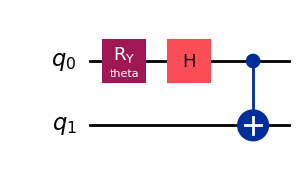

In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

# circuit for which you want to obtain the expected value
circuit = QuantumCircuit(2)
circuit.ry(Parameter("theta"), 0)
circuit.h(0)
circuit.cx(0, 1)
circuit.draw("mpl", style="iqp")

In [12]:
from qiskit.quantum_info import SparsePauliOp
import numpy as np

# observable(s) whose expected values you want to compute

observable = SparsePauliOp(["II", "XX", "YY", "ZZ"], coeffs=[1, 1, -1, 1])

# value(s) for the circuit parameter(s)
parameter_values = [[0], [np.pi / 6], [np.pi / 2]]

In [15]:
# Generate a pass manager without providing a backend
from qiskit.transpiler import generate_preset_pass_manager

pm = generate_preset_pass_manager(optimization_level=1)
isa_circuit = pm.run(circuit)
isa_observable = observable.apply_layout(isa_circuit.layout)
from qiskit.primitives import StatevectorEstimator

estimator = StatevectorEstimator()
job = estimator.run([(circuit, observable, parameter_values)])
result = job.result()
print(f" > Result class: {type(result)}")

 > Result class: <class 'qiskit.primitives.containers.primitive_result.PrimitiveResult'>


In [16]:
print(f" > Expectation value: {result[0].data.evs}")
print(f" > Metadata: {result[0].metadata}")

 > Expectation value: [4.         3.73205081 2.        ]
 > Metadata: {'target_precision': 0.0, 'circuit_metadata': {}}


In [17]:
# Estimate expectation values for two PUBs, both with 0.05 precision.
precise_job = estimator.run(
    [(circuit, observable, parameter_values)], precision=0.05
)

In [3]:
circuit = QuantumCircuit(3, 3)
circuit.x(1)
circuit.h(range(3))
circuit.cx(0, 1)
circuit.measure(range(3), range(3));

In [ ]:
# Latex drawing
circuit.draw(output="latex")

In [ ]:
# Save as an image using the Matplotlib drawer
circuit.draw(output="mpl", filename="circuit-mpl.jpeg")